# 04 · Q-learning tabular: aprender sin el modelo
**Entornos:** MiniDespacho (diminuto) · **Tiempo de ejecución:** ≤ 5 min en CPU · **Criterio de la lección:** la política aprendida por Q-learning alcanza ≥ 95 % del valor
óptimo de value iteration (LB del IC 95 % de la diferencia pareada ≥ −0,05·|V\*|, n = 2000 episodios).

## 1. La idea en una frase
Sin conocer $P$ ni $R$, un agente puede estimar $Q(s,a)$ **solo con la experiencia**: cada transición observada corrige un poco su estimación (aprendizaje por diferencia temporal).

**En el sistema de Luca:** el mismo error TD $r + \gamma V(s') - V(s)$ es la base de GAE y del crítico de PPO; solo cambia la tabla por una red.
**En un problema de negocio:** aprender una regla de despacho jugando sobre un simulador cuya dinámica no se conoce en forma cerrada.

## 2. La intuición y la fórmula
Tras observar $(s, a, r, s')$:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\bigl[\, r + \gamma \max_{a' \in \text{legales}(s')} Q(s',a') - Q(s,a) \,\bigr]$$

El agente elige con **ε-greedy sobre las opciones legales**: con probabilidad ε una opción al azar, si no la de mayor $Q$. En el estado terminal el objetivo es solo $r$.
$\gamma$ descuenta el futuro; el entorno evalúa retornos **sin descontar**, así que $\gamma<1$ introduce un sesgo que los experimentos miden.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, derive_seed, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, passes_lower
from rlf.envs.despacho import DespachoConfig, DespachoEnv, build_mdp
from rlf.agents.tabular import QLearning, value_iteration
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)

cfg = DespachoConfig.from_size("diminuto")
mdp = build_mdp(cfg)
V, Q_star, policy_opt = value_iteration(mdp, gamma=1.0)
v_star = float(mdp.p0 @ V)
make_env = lambda: DespachoEnv.from_size("diminuto")
print(f"V* = {v_star:.4f} (value iteration, lección 3)")

V* = -4.2049 (value iteration, lección 3)


## 3. El núcleo: la actualización y el bucle de entrenamiento
Escrito inline. Una celda comprueba que da **exactamente** la misma tabla que `rlf.agents.tabular.QLearning`.

In [2]:
def q_learning_inline(env, n_episodes, alpha, gamma, eps_fn, seed):
    """Q-learning tabular. Q[estado] es un vector sobre los ids globales de acción; solo se usan los ids legales."""
    rng = np.random.default_rng(seed)
    Q, returns = {}, np.zeros(n_episodes)
    def q_of(key):
        if key not in Q:
            Q[key] = np.zeros(3)                                   # n_actions = 3 en "diminuto"
        return Q[key]
    for e in range(n_episodes):
        eps = eps_fn(e)
        obs = env.reset(derive_seed(seed, 0, e))                   # semillas de ENTRENAMIENTO
        key, done = env.state_key(), False
        while not done:
            ids = obs.option_ids                                   # ids legales de esta observación
            if eps > 0 and rng.random() < eps:
                j = int(rng.integers(len(ids)))                    # explorar: opción legal al azar
            else:
                j = int(np.argmax(q_of(key)[ids]))                 # explotar: mejor Q entre las legales
            st = env.step(j)
            key2 = env.state_key()
            a = int(ids[j])
            # objetivo TD: r (si terminó) o r + γ max_a' Q(s', a') sobre las opciones legales de s'
            target = st.rewards[0] if st.done else st.rewards[0] + gamma * q_of(key2)[st.obs.option_ids].max()
            q_of(key)[a] += alpha * (target - q_of(key)[a])
            returns[e] += st.rewards[0]
            key, obs, done = key2, st.obs, st.done
    return Q, returns

# verificación cruzada: misma tabla que la versión de rlf (mismas semillas, mismo consumo de azar)
Q_a, _ = q_learning_inline(make_env(), 3000, 0.1, 1.0, lambda e: 0.2, seed=5)
ref = QLearning(3, alpha=0.1, gamma=1.0, eps=0.2, seed=5)
ref.train(make_env(), 3000, seed=5)
assert Q_a.keys() == ref.Q.keys() and all(np.array_equal(Q_a[k], ref.Q[k]) for k in Q_a)
print(f"inline == rlf: {len(Q_a)} estados idénticos")

inline == rlf: 1854 estados idénticos


## 4. Entrenar y graficar la curva de aprendizaje
200 000 episodios (≈ 1,6 millones de pasos de entorno) con ε decreciente de 0,3 a 0,02. Cada cierto número de episodios evaluamos **exactamente** la política greedy
con `build_mdp` (evaluación de política sobre el MDP, sin ruido de simulación) y la comparamos con $V^*$.

   1000 episodios: valor de la política greedy = -6.606  (1.571 × V*)


   2000 episodios: valor de la política greedy = -5.575  (1.326 × V*)


   5000 episodios: valor de la política greedy = -4.700  (1.118 × V*)


  10000 episodios: valor de la política greedy = -4.364  (1.038 × V*)


  20000 episodios: valor de la política greedy = -4.368  (1.039 × V*)


  50000 episodios: valor de la política greedy = -4.352  (1.035 × V*)


 100000 episodios: valor de la política greedy = -4.364  (1.038 × V*)


 200000 episodios: valor de la política greedy = -4.270  (1.016 × V*)


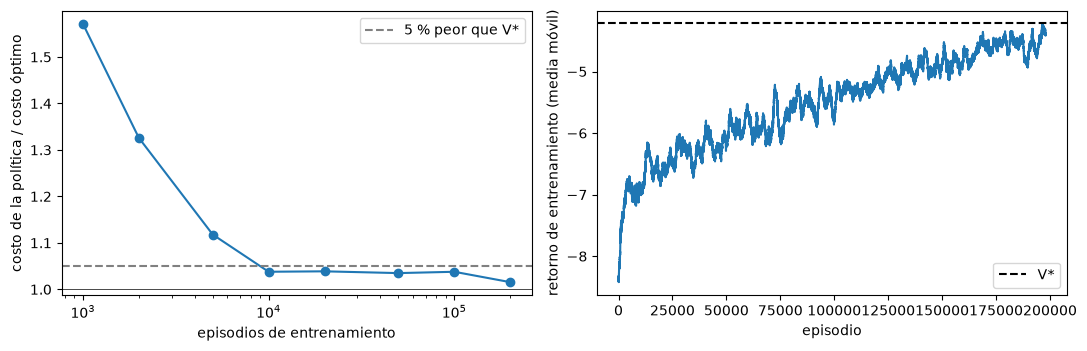

In [3]:
nS, nA = mdp.legal.shape
flat = mdp.src * nA + mdp.act
def greedy_policy_value(Q):
    """Valor esperado exacto (γ=1) de la política greedy de Q, por evaluación de política sobre el MDP."""
    pol = np.array([-1 if mdp.terminal[s] else int(np.argmax(np.where(mdp.legal[s], Q.get(k, np.zeros(3)), -np.inf)))
                    for s, k in enumerate(mdp.keys)])
    Vp = np.zeros(nS)
    for _ in range(30):
        EV = np.bincount(flat, weights=mdp.prob * Vp[mdp.dst], minlength=nS * nA).reshape(nS, nA)
        Vp = np.where(mdp.terminal, 0.0, (mdp.R + EV)[np.arange(nS), np.maximum(pol, 0)])
    return float(mdp.p0 @ Vp)

N_MAIN = 200_000
CHECKPOINTS = [1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]
eps_main = lambda e: max(0.02, 0.3 * (1 - e / N_MAIN))
ratios, main_returns = {}, np.zeros(N_MAIN)
done_eps = 0
env = make_env()
# entrenamos por tramos para evaluar en cada checkpoint, continuando la MISMA tabla
agent = QLearning(3, alpha=0.1, gamma=1.0, eps=0.3, seed=TRAIN_SEED)
for cp in CHECKPOINTS:
    part = agent.train(env, cp - done_eps, seed=TRAIN_SEED * 1000 + done_eps, eps_fn=lambda e, d=done_eps: eps_main(d + e))
    main_returns[done_eps:cp] = part
    done_eps = cp
    ratios[cp] = greedy_policy_value(agent.Q) / v_star
    print(f"{cp:7d} episodios: valor de la política greedy = {ratios[cp] * v_star:.3f}  ({ratios[cp]:.3f} × V*)")
Q_main = agent.Q

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(list(ratios), list(ratios.values()), marker="o"); ax[0].axhline(1.05, color="gray", ls="--", label="5 % peor que V*"); ax[0].axhline(1.0, color="k", lw=0.5)
ax[0].set_xscale("log"); ax[0].set_xlabel("episodios de entrenamiento"); ax[0].set_ylabel("costo de la política / costo óptimo"); ax[0].legend()
w = 2000; ma = np.convolve(main_returns, np.ones(w) / w, mode="valid")
ax[1].plot(ma); ax[1].axhline(v_star, color="k", ls="--", label="V*"); ax[1].set_xlabel("episodio"); ax[1].set_ylabel("retorno de entrenamiento (media móvil)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"
Cada experimento entrena 40 000 episodios (≈ 20 s) y mide el valor **exacto** de la política greedy resultante.

In [4]:
N_EXP = 40_000
def train_exp(gamma, eps_fn):
    ag = QLearning(3, alpha=0.1, gamma=gamma, eps=0.3, seed=TRAIN_SEED)
    rets = ag.train(make_env(), N_EXP, seed=TRAIN_SEED, eps_fn=eps_fn)
    return ag, rets
eps_decay = lambda e: max(0.02, 0.3 * (1 - e / N_EXP))
RUN = {}
RUN["decay γ=1.0"] = train_exp(1.0, eps_decay)

### Experimento 1 · ε constante 0,3 vs decreciente
**Predice:** ¿cuál produce la mejor política greedy? ¿y el mejor retorno **durante** el entrenamiento?

In [5]:
RUN["const γ=1"] = train_exp(1.0, lambda e: 0.3)
r_const, r_decay = (greedy_policy_value(RUN[k][0].Q) / v_star for k in ("const γ=1", "decay γ=1.0"))
on_const, on_decay = RUN["const γ=1"][1][-2000:].mean(), RUN["decay γ=1.0"][1][-2000:].mean()
print(f"política greedy (× V*): constante {r_const:.3f}, decreciente {r_decay:.3f}")
print(f"retorno online (últimos 2000 episodios): constante {on_const:.2f}, decreciente {on_decay:.2f}  (V* = {v_star:.2f})")
assert r_const <= 1.10 and r_decay <= 1.10          # ambas políticas greedy quedan a ≤ 10 % del óptimo
assert on_decay > on_const + 1.0                     # pero explorar siempre cuesta retorno mientras se entrena

política greedy (× V*): constante 1.036, decreciente 1.060
retorno online (últimos 2000 episodios): constante -7.16, decreciente -4.70  (V* = -4.20)


<details><summary>Respuesta esperada</summary>

Las dos políticas greedy quedan parecidas y cerca del óptimo (≈ 1,04–1,06 × V*): Q-learning es *off-policy*, aprende $Q^*$ aunque explore.
La diferencia está en el retorno **durante** el entrenamiento: con ε = 0,3 fijo se pierden ≈ 2,5 unidades por episodio (≈ −7,2 frente a ≈ −4,7 con ε decreciente).
Explorar es una inversión: hay que dejar de pagarla cuando ya se aprendió.
</details>

### Experimento 2 · γ = 0,5 vs 0,9 vs 1,0 evaluados en retorno sin descontar
**Predice:** ¿empeora la política con γ < 1? ¿y los valores $Q$ que aprende?

In [6]:
RUN["decay γ=0.5"] = train_exp(0.5, eps_decay)
RUN["decay γ=0.9"] = train_exp(0.9, eps_decay)
init_key = mdp.keys[int(np.flatnonzero(mdp.p0 == mdp.p0.max())[0])]        # estado inicial sin pedido
rat = {g: greedy_policy_value(RUN[f"decay γ={g}"][0].Q) / v_star for g in (0.5, 0.9, 1.0)}
q_init = {g: float(RUN[f"decay γ={g}"][0].Q[init_key][2]) for g in (0.5, 0.9, 1.0)}     # id 2 = esperar, la única opción legal
print("política greedy (× V*):", {g: round(v, 3) for g, v in rat.items()})
print("valor aprendido del estado inicial, Q(esperar):", {g: round(v, 3) for g, v in q_init.items()}, f"(V* del estado = {V[mdp.index[init_key]]:.3f})")
assert max(rat.values()) <= 1.10 and max(rat.values()) - min(rat.values()) < 0.08
assert abs(q_init[0.5]) < 0.8 * abs(q_init[1.0]) and abs(q_init[0.9]) < abs(q_init[1.0])

política greedy (× V*): {0.5: 1.011, 0.9: 1.016, 1.0: 1.06}
valor aprendido del estado inicial, Q(esperar): {0.5: -0.418, 0.9: -1.706, 1.0: -2.628} (V* del estado = -2.564)


<details><summary>Respuesta esperada</summary>

La **política** casi no cambia (todas a ≈ 1,01–1,06 × V*): con horizonte de solo 6 ticks, descontar rara vez altera cuál acción es mejor. Lo que sí cambia son los **valores**:
con γ = 0,5 el valor aprendido del estado inicial es mucho menor en magnitud que el real, porque el agente "no ve" los costos futuros. Para reportar retornos hay que evaluar sin descontar,
aunque se entrene con γ < 1.
</details>

### Experimento 3 · ¿Cuántos episodios hacen falta para llegar al 95 %?
**Predice:** ¿del orden de cientos, miles o cientos de miles de episodios? (usa la curva de la sección 4).

In [7]:
first = next(cp for cp in CHECKPOINTS if all(ratios[c] <= 1.05 for c in CHECKPOINTS if c >= cp))
print("checkpoint desde el cual la política se mantiene a ≤ 5 % de V*:", first, {c: round(r, 3) for c, r in ratios.items()})
assert first <= 50_000 and ratios[200_000] <= 1.05 and ratios[1000] > 1.05

checkpoint desde el cual la política se mantiene a ≤ 5 % de V*: 10000 {1000: 1.571, 2000: 1.326, 5000: 1.118, 10000: 1.038, 20000: 1.039, 50000: 1.035, 100000: 1.038, 200000: 1.016}


<details><summary>Respuesta esperada</summary>

Del orden de **decenas de miles** de episodios (la política queda a ≤ 5 % de $V^*$ desde ≈ 10 000–20 000): con mil episodios todavía está lejos (≈ 1,6 × V*).
Para un problema con 2336 estados alcanzables y 3 acciones ya es mucha experiencia; una tabla no escala a problemas con millones de estados (lección 5).
</details>

### Experimento 4 · ¿Qué fracción de los estados alcanzables se visitó?
**Predice:** tras 200 000 episodios, ¿la tabla cubre casi todos los estados o solo una parte?

In [8]:
reach = {k for k in mdp.keys if not mdp.terminal[mdp.index[k]]}
visited = {k for k in Q_main if k in reach}
frac = len(visited) / len(reach)
print(f"estados alcanzables no terminales: {len(reach)}; visitados: {len(visited)} ({100 * frac:.1f} %)")
assert frac > 0.95

estados alcanzables no terminales: 2336; visitados: 2329 (99.7 %)


<details><summary>Respuesta esperada</summary>

Casi todos (≈ 99,7 %: 2329 de 2336): en "diminuto" el espacio de estados es chico y la política aleatoria de exploración lo recorre entero. Los pocos que faltan son estados muy improbables.
En "mediano" no ocurriría: ahí cada episodio casi siempre pisa estados nuevos (lección 5).
</details>

## 6. Criterio de la lección
n = 2000 episodios de evaluación con semillas `EVAL_SEED_BASE + i`, política greedy (ε = 0), γ = 1, contra la política óptima de `value_iteration`.

In [9]:
N = 2000
def optimal_returns(n):
    env = make_env(); out = np.zeros(n)
    for i in range(n):
        obs = env.reset(EVAL_SEED_BASE + i); done = False
        while not done:
            a_id = policy_opt[mdp.index[env.state_key()]]
            st = env.step(int(np.flatnonzero(obs.option_ids == a_id)[0]))
            out[i] += st.rewards[0]; obs, done = st.obs, st.done
    return out

learned = agent.evaluate(make_env, N)
optimal = optimal_returns(N)
diff = paired_diff_ci(learned, optimal)
threshold = -0.05 * abs(v_star)
ok_a = diff.n == N and passes_lower(diff, threshold)
print(f"{'afirmación':70s} resultado")
print(f"{'(a) aprendida − óptima = %.3f  IC95 [%.3f, %.3f];  LB ≥ %.3f (−0,05·|V*|)' % (diff.mean, diff.lo, diff.hi, threshold):70s} {ok_a}")
assert ok_a

afirmación                                                             resultado
(a) aprendida − óptima = -0.038  IC95 [-0.083, 0.006];  LB ≥ -0.210 (−0,05·|V*|) True


## 7. Resumen y puente a la lección siguiente
- Q-learning aprendió, **sin conocer el modelo**, una política a ≤ 5 % del óptimo de value iteration, con la misma actualización TD que reaparecerá en el crítico de PPO.
- Explorar cuesta retorno durante el entrenamiento pero no impide aprender $Q^*$; γ < 1 sesga los valores más que la política.
- **Lección 5:** la tabla necesitó decenas de miles de episodios para 2336 estados. En "mediano" hay órdenes de magnitud más: hay que **generalizar** con una red neuronal (DQN).